## Inicializa o principais dependencias

In [1]:
%run "../0 - Base/inicializa.ipynb"

In [2]:
GoldVendas = pd.read_csv("C:\\Users\\Public\\Teste_Jupyter\\Mercado\\2 - Silver\\silverVendas_ETL.csv")

In [3]:
GoldVendas['OPERADOR'].value_counts()

OPERADOR
JULIANA           8950
PATRICIA          6012
CARLOS_GER         309
N_IDENTIFICADO     284
Name: count, dtype: int64

In [4]:
GoldVendas['COD_PRODUTO'].duplicated().value_counts() # Valida quanto produtos repeditos

COD_PRODUTO
True     15798
False       24
Name: count, dtype: int64

In [5]:
GoldVendas['ID_TRANSACAO'].duplicated().value_counts()

ID_TRANSACAO
False    15822
Name: count, dtype: int64

In [6]:
GoldVendas['COD_PRODUTO'].isna().value_counts()

COD_PRODUTO
False    15822
Name: count, dtype: int64

In [7]:
GoldVendas['COD_PRODUTO'].fillna(1000001) # Confirma valores null igual 1000001

GoldVendas['COD_PRODUTO'].value_counts()

COD_PRODUTO
1000001.0    1306
102.0         684
403.0         680
302.0         672
104.0         667
201.0         661
105.0         659
401.0         650
501.0         645
999.0         643
103.0         632
301.0         631
303.0         627
101.0         623
202.0         620
203.0         619
503.0         614
502.0         608
304.0         607
204.0         606
601.0         602
602.0         601
402.0         600
404.0         565
Name: count, dtype: int64

-------

In [8]:
g_id_test = (
    GoldVendas
    .groupby(['PDV_CAIXA'], as_index=False)
    .agg(
        QTD_TOTAL=('QTD_VENDIDA', 'sum'),
        PRECO_UN=('PRECO_UNIT_COBRADO', 'mean'),
        TOTAL=('TOTAL_PAGO', 'sum'),
    )
)
g_id_test.head(3)
    


,PDV_CAIXA,QTD_TOTAL,PRECO_UN,TOTAL
0,CAIXA_01,18793.0,20.115793,253815.99
1,CAIXA_02,19042.0,20.172637,262752.77
2,CAIXA_P,9589.0,20.276261,128483.58


Text(0.5, 1.0, 'TEST')

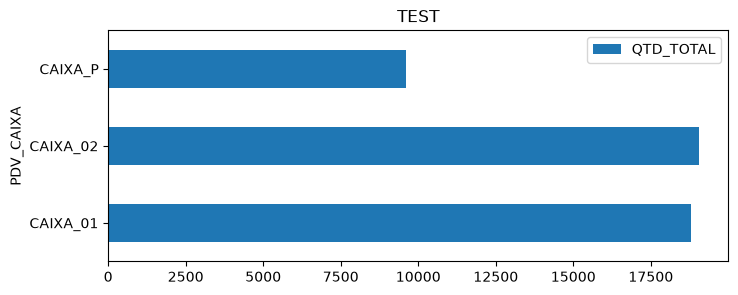

In [9]:
g_id_test.plot(
    kind='barh',
    x='PDV_CAIXA',
    y='QTD_TOTAL',
    figsize=(8, 3),
    legend=True
)

plt.title('TEST')

------

# CRIA NOVAS TABELAS

### Agrupa por ID

In [10]:
g_id_qtd = (
    GoldVendas
    .groupby('ID_TRANSACAO', as_index=False)['QTD_VENDIDA']
    .sum()
)
g_id_qtd.head(3)

,ID_TRANSACAO,QTD_VENDIDA
0,900001,5.0
1,900002,2.0
2,900003,4.0


In [11]:
g_id_unit = (
    GoldVendas
    .groupby('ID_TRANSACAO', as_index=False)['PRECO_UNIT_COBRADO']
    .sum()
)
g_id_unit.head(3)

,ID_TRANSACAO,PRECO_UNIT_COBRADO
0,900001,3.94
1,900002,34.47
2,900003,32.32


In [12]:
g_id_total = (
    GoldVendas
    .groupby('ID_TRANSACAO', as_index=False)['TOTAL_PAGO']
    .sum()
)
g_id_total.head(3)

,ID_TRANSACAO,TOTAL_PAGO
0,900001,19.70
1,900002,68.94
2,900003,129.28


In [13]:
g_id = pd.concat(
    [g_id_qtd['ID_TRANSACAO'], g_id_qtd['QTD_VENDIDA'], g_id_unit['PRECO_UNIT_COBRADO'], g_id_total['TOTAL_PAGO']],
    axis=1
)
g_id.head(3)

,ID_TRANSACAO,QTD_VENDIDA,PRECO_UNIT_COBRADO,TOTAL_PAGO
0,900001,5.0,3.94,19.70
1,900002,2.0,34.47,68.94
2,900003,4.0,32.32,129.28


-------

### Agrupa por Caixa

In [14]:
g_cx_qtd = (
    GoldVendas
    .groupby('PDV_CAIXA', as_index=False)['QTD_VENDIDA']
    .sum()
)
g_cx_qtd.head(3)

,PDV_CAIXA,QTD_VENDIDA
0,CAIXA_01,18793.0
1,CAIXA_02,19042.0
2,CAIXA_P,9589.0


In [15]:
g_cx_unit = (
    GoldVendas
    .groupby('PDV_CAIXA', as_index=False)['PRECO_UNIT_COBRADO']
    .sum()
)
g_cx_unit.head(3)

,PDV_CAIXA,PRECO_UNIT_COBRADO
0,CAIXA_01,126367.41
1,CAIXA_02,128519.87
2,CAIXA_P,64255.47


In [16]:
g_cx_total = (
    GoldVendas
    .groupby('PDV_CAIXA', as_index=False)['TOTAL_PAGO']
    .sum()
)
g_cx_total.head(3)

,PDV_CAIXA,TOTAL_PAGO
0,CAIXA_01,253815.99
1,CAIXA_02,262752.77
2,CAIXA_P,128483.58


In [17]:
g_caixa = pd.concat(
    [g_cx_qtd['PDV_CAIXA'], g_cx_qtd['QTD_VENDIDA'], g_cx_unit['PRECO_UNIT_COBRADO'], g_cx_total['TOTAL_PAGO']],
    axis=1
)
g_caixa.head(3)

,PDV_CAIXA,QTD_VENDIDA,PRECO_UNIT_COBRADO,TOTAL_PAGO
0,CAIXA_01,18793.0,126367.41,253815.99
1,CAIXA_02,19042.0,128519.87,262752.77
2,CAIXA_P,9589.0,64255.47,128483.58


----

### Operdor

In [18]:
g_op_qtd = (
    GoldVendas
    .groupby('OPERADOR', as_index=False)['QTD_VENDIDA']
    .sum()
)
g_op_qtd.head(3)

,OPERADOR,QTD_VENDIDA
0,CARLOS_GER,933.0
1,JULIANA,26862.0
2,N_IDENTIFICADO,849.0


In [19]:
g_op_unit = (
    GoldVendas
    .groupby('OPERADOR', as_index=False)['PRECO_UNIT_COBRADO']
    .sum()
)
g_op_unit.head(3)

,OPERADOR,PRECO_UNIT_COBRADO
0,CARLOS_GER,6326.49
1,JULIANA,180505.69
2,N_IDENTIFICADO,5594.18


In [20]:
g_op_total = (
    GoldVendas
    .groupby('OPERADOR', as_index=False)['TOTAL_PAGO']
    .sum()
)
g_op_total.head(3)

,OPERADOR,TOTAL_PAGO
0,CARLOS_GER,12033.08
1,JULIANA,362366.23
2,N_IDENTIFICADO,10741.34


In [21]:
g_operador = pd.concat(
    [g_op_qtd['OPERADOR'], g_op_qtd['QTD_VENDIDA'], g_op_unit['PRECO_UNIT_COBRADO'], g_op_total['TOTAL_PAGO']],
    axis=1
)
g_operador.head(3)

,OPERADOR,QTD_VENDIDA,PRECO_UNIT_COBRADO,TOTAL_PAGO
0,CARLOS_GER,933.0,6326.49,12033.08
1,JULIANA,26862.0,180505.69,362366.23
2,N_IDENTIFICADO,849.0,5594.18,10741.34


----

### Cod_Produto

In [22]:
g_cod_qtd = (
    GoldVendas
    .groupby('COD_PRODUTO', as_index=False)['QTD_VENDIDA']
    .sum()
)
g_cod_qtd.head(3)

,COD_PRODUTO,QTD_VENDIDA
0,101.0,1890.0
1,102.0,2067.0
2,103.0,1831.0


In [23]:
g_cod_unit = (
    GoldVendas
    .groupby('COD_PRODUTO', as_index=False)['PRECO_UNIT_COBRADO']
    .sum()
)
g_cod_unit.head(3)

,COD_PRODUTO,PRECO_UNIT_COBRADO
0,101.0,12743.10
1,102.0,14095.12
2,103.0,12987.12


In [24]:
g_cod_total = (
    GoldVendas
    .groupby('COD_PRODUTO', as_index=False)['TOTAL_PAGO']
    .sum()
)
g_cod_total.head(3)

,COD_PRODUTO,TOTAL_PAGO
0,101.0,25935.86
1,102.0,29890.43
2,103.0,26014.99


In [25]:
g_cod = (
    GoldVendas
    .groupby('COD_PRODUTO', as_index=False)
    .agg(
        QTD_VENDIDA=('QTD_VENDIDA', 'sum'),
        FATURAMENTO=('TOTAL_PAGO', 'sum'),
    )
)
g_cod['PRECO_MEDIO'] = g_cod['FATURAMENTO'] / g_cod['QTD_VENDIDA']

In [26]:
# g_cod = pd.concat(
#     [g_cod_qtd['COD_PRODUTO'], g_cod_qtd['QTD_VENDIDA'], g_cod_unit['PRECO_UNIT_COBRADO'], g_cod_total['TOTAL_PAGO']],
#     axis=1
# )
# g_cod.head(3)

----

### Forma pag

In [27]:
g_fpagamento_qtd = (
    GoldVendas
    .groupby('FORMA_PAGTO', as_index=False)['QTD_VENDIDA']
    .sum()
)
g_fpagamento_qtd.head(3)

,FORMA_PAGTO,QTD_VENDIDA
0,CARTAO_CRED,5819.0
1,CARTAO_DEB,6143.0
2,DINHEIRO,5833.0


In [28]:
g_fpagamento_unit = (
    GoldVendas
    .groupby('FORMA_PAGTO', as_index=False)['PRECO_UNIT_COBRADO']
    .sum()
)
g_fpagamento_unit.head(3)

,FORMA_PAGTO,PRECO_UNIT_COBRADO
0,CARTAO_CRED,38718.84
1,CARTAO_DEB,40931.62
2,DINHEIRO,39611.40


In [29]:
g_fpagamento_total = (
    GoldVendas
    .groupby('FORMA_PAGTO', as_index=False)['TOTAL_PAGO']
    .sum()
)
g_fpagamento_total.head(3)

,FORMA_PAGTO,TOTAL_PAGO
0,CARTAO_CRED,77933.86
1,CARTAO_DEB,84828.50
2,DINHEIRO,77372.83


In [30]:
g_forma_pagamento = pd.concat(
    [g_fpagamento_qtd['FORMA_PAGTO'], g_fpagamento_qtd['QTD_VENDIDA'], g_fpagamento_unit['PRECO_UNIT_COBRADO'], g_fpagamento_total['TOTAL_PAGO']],
    axis=1
)
g_forma_pagamento.head(3)

,FORMA_PAGTO,QTD_VENDIDA,PRECO_UNIT_COBRADO,TOTAL_PAGO
0,CARTAO_CRED,5819.0,38718.84,77933.86
1,CARTAO_DEB,6143.0,40931.62,84828.50
2,DINHEIRO,5833.0,39611.40,77372.83


----

### Status

In [31]:
g_status_qtd = (
    GoldVendas
    .groupby('STATUS_VENDA', as_index=False)['QTD_VENDIDA']
    .sum()
)
g_status_qtd.head(3)

,STATUS_VENDA,QTD_VENDIDA
0,ABERTO,6748.0
1,CANCELADA,6525.0
2,CONCLUIDA,27302.0


In [32]:
g_status_unit = (
    GoldVendas
    .groupby('STATUS_VENDA', as_index=False)['PRECO_UNIT_COBRADO']
    .sum()
)
g_status_unit.head(3)

,STATUS_VENDA,PRECO_UNIT_COBRADO
0,ABERTO,52637.00
1,CANCELADA,0.00
2,CONCLUIDA,212733.18


In [33]:
g_status_total = (
    GoldVendas
    .groupby('STATUS_VENDA', as_index=False)['TOTAL_PAGO']
    .sum()
)
g_status_total.head(3)

,STATUS_VENDA,TOTAL_PAGO
0,ABERTO,0.00
1,CANCELADA,0.00
2,CONCLUIDA,645052.34


In [34]:
g_status = pd.concat(
    [g_status_qtd['STATUS_VENDA'], g_status_qtd['QTD_VENDIDA'], g_status_unit['PRECO_UNIT_COBRADO'], g_status_total['TOTAL_PAGO']],
    axis=1
)
g_status.head(3)

,STATUS_VENDA,QTD_VENDIDA,PRECO_UNIT_COBRADO,TOTAL_PAGO
0,ABERTO,6748.0,52637.00,0.00
1,CANCELADA,6525.0,0.00,0.00
2,CONCLUIDA,27302.0,212733.18,645052.34


----

### Ano

In [35]:
g_ano_qtd = (
    GoldVendas
    .groupby('ANO', as_index=False)['QTD_VENDIDA']
    .sum()
)
g_ano_qtd.head(3)

,ANO,QTD_VENDIDA
0,2026,47424.0


In [36]:
g_ano_unit = (
    GoldVendas
    .groupby('ANO', as_index=False)['PRECO_UNIT_COBRADO']
    .sum()
)
g_ano_unit.head(3)

,ANO,PRECO_UNIT_COBRADO
0,2026,319142.75


In [37]:
g_ano_total = (
    GoldVendas
    .groupby('ANO', as_index=False)['TOTAL_PAGO']
    .sum()
)
g_ano_total.head(3)

,ANO,TOTAL_PAGO
0,2026,645052.34


In [38]:
g_ano = pd.concat(
    [g_ano_qtd['ANO'], g_ano_qtd['QTD_VENDIDA'], g_ano_unit['PRECO_UNIT_COBRADO'], g_ano_total['TOTAL_PAGO']],
    axis=1
)
g_ano.head(3)

,ANO,QTD_VENDIDA,PRECO_UNIT_COBRADO,TOTAL_PAGO
0,2026,47424.0,319142.75,645052.34


----

### Mes

In [39]:
g_mes_qtd = (
    GoldVendas
    .groupby('MES', as_index=False)['QTD_VENDIDA']
    .sum()
)
g_mes_qtd.head(3)

,MES,QTD_VENDIDA
0,1,13150.0
1,2,11394.0
2,3,13656.0


In [40]:
g_mes_unit = (
    GoldVendas
    .groupby('MES', as_index=False)['PRECO_UNIT_COBRADO']
    .sum()
)
g_mes_unit.head(3)

,MES,PRECO_UNIT_COBRADO
0,1,88762.04
1,2,76773.02
2,3,92865.81


In [41]:
g_mes_total = (
    GoldVendas
    .groupby('MES', as_index=False)['TOTAL_PAGO']
    .sum()
)
g_mes_total.head(3)

,MES,TOTAL_PAGO
0,1,177091.79
1,2,154554.71
2,3,188314.40


In [42]:
g_mes = pd.concat(
    [g_mes_qtd['MES'], g_mes_qtd['QTD_VENDIDA'], g_mes_unit['PRECO_UNIT_COBRADO'], g_mes_total['TOTAL_PAGO']],
    axis=1
)
g_mes.head(3)

,MES,QTD_VENDIDA,PRECO_UNIT_COBRADO,TOTAL_PAGO
0,1,13150.0,88762.04,177091.79
1,2,11394.0,76773.02,154554.71
2,3,13656.0,92865.81,188314.40


----

In [43]:
GoldVendas['COD_PRODUTO'].isna().value_counts()

COD_PRODUTO
False    15822
Name: count, dtype: int64

----

### Criado pelo claude, ainda nao entendi muito bem

In [44]:
# Quantas linhas por transação?
print("Transações com mais de uma linha:", GoldVendas['ID_TRANSACAO'].duplicated().sum())

# TOTAL_PAGO varia dentro da mesma transação? (se não, está repetido por item)
print("Máximo de valores distintos por transação:",
      GoldVendas.groupby('ID_TRANSACAO')['TOTAL_PAGO'].nunique().max())

# QTD * PRECO_UNIT bate com TOTAL_PAGO por linha?
diferenca = (GoldVendas['QTD_VENDIDA'] * GoldVendas['PRECO_UNIT_COBRADO'] - GoldVendas['TOTAL_PAGO']).abs()
print("Linhas com diferença > 0,01:", (diferenca > 0.01).sum())

Transações com mais de uma linha: 0
Máximo de valores distintos por transação: 1
Linhas com diferença > 0,01: 4545


In [45]:
print(GoldVendas.groupby('STATUS_VENDA', as_index=False).agg(
    VALOR=('TOTAL_PAGO', 'sum'),
    LINHAS=('ID_TRANSACAO', 'size'),
))

  STATUS_VENDA      VALOR  LINHAS
0       ABERTO       0.00    2247
1    CANCELADA       0.00    2226
2    CONCLUIDA  645052.34    9051
3    ESTORNADA       0.00    2298


In [46]:
STATUS_FATURADO = 'CONCLUIDA'
STATUS_CONHECIDOS = {'CONCLUIDA', 'ESTORNADA', 'CANCELADA', 'ABERTO'}

status_novos = set(GoldVendas['STATUS_VENDA'].unique()) - STATUS_CONHECIDOS
assert not status_novos, f"Status não previstos: {status_novos}"

GoldVendasValidas = GoldVendas[GoldVendas['STATUS_VENDA'] == STATUS_FATURADO].copy()


In [47]:
def resumo_vendas(coluna):
    return (
        GoldVendasValidas
        .groupby(coluna, as_index=False)
        .agg(
            FATURAMENTO=('TOTAL_PAGO', 'sum'),
            QTD_VENDIDA=('QTD_VENDIDA', 'sum'),
            TRANSACOES=('ID_TRANSACAO', 'nunique'),
        )
        .assign(
            PRECO_MEDIO=lambda d: d['FATURAMENTO'] / d['QTD_VENDIDA'],
            TICKET_MEDIO=lambda d: d['FATURAMENTO'] / d['TRANSACOES'],
        )
        .sort_values('FATURAMENTO', ascending=False)
    )

g_id = GoldVendasValidas.groupby('ID_TRANSACAO', as_index=False)\
    .agg(
    QTD_VENDIDA=('QTD_VENDIDA', 'sum'),
    FATURAMENTO=('TOTAL_PAGO', 'sum'),
    TRANSACOES=('ID_TRANSACAO', 'nunique'),
).assign(
            PRECO_MEDIO=lambda d: d['FATURAMENTO'] / d['QTD_VENDIDA'],
        )
g_caixa = resumo_vendas('PDV_CAIXA')
g_operador = resumo_vendas('OPERADOR')
g_cod = resumo_vendas('COD_PRODUTO')
g_forma_pagamento = resumo_vendas('FORMA_PAGTO')
g_ano = resumo_vendas('ANO')
g_mes = resumo_vendas(['ANO', 'MES'])

In [48]:
GoldVendasValidas.head(5)

,ID_TRANSACAO,DATA_HORA_VENDA,PDV_CAIXA,OPERADOR,COD_PRODUTO,QTD_VENDIDA,PRECO_UNIT_COBRADO,TOTAL_PAGO,FORMA_PAGTO,STATUS_VENDA,MES,ANO
0,900001,2026-01-01,CAIXA_P,JULIANA,503.0,5.0,3.94,19.70,FIADO_CADERNETO,CONCLUIDA,1,2026
1,900002,2026-01-01,CAIXA_02,PATRICIA,1000001.0,2.0,34.47,68.94,FIADO_CADERNETO,CONCLUIDA,1,2026
2,900003,2026-01-01,CAIXA_02,PATRICIA,404.0,4.0,32.32,129.28,FIADO_CADERNETO,CONCLUIDA,1,2026
3,900004,2026-01-01,CAIXA_02,PATRICIA,303.0,4.0,36.05,144.20,CARTAO_CRED,CONCLUIDA,1,2026
4,900005,2026-01-01,CAIXA_02,PATRICIA,304.0,5.0,25.25,126.25,CARTAO_DEB,CONCLUIDA,1,2026


In [49]:
transacoes = GoldVendasValidas.drop_duplicates('ID_TRANSACAO')


## NOVAS

In [50]:
# cria tabela, agrupa por operador com agregaçãodos id
g_op_x_id = (
    GoldVendas
    .groupby('OPERADOR', as_index=False)['ID_TRANSACAO']
    .sum()
)
g_op_x_id.head(10)

,OPERADOR,ID_TRANSACAO
0,CARLOS_GER,280510519
1,JULIANA,8125314984
2,N_IDENTIFICADO,257931850
3,PATRICIA,5458946261


In [51]:
# cria tabela, agrupa por codigo produto com agregaçãodos id
g_cod_x_id = (
    GoldVendas
    .groupby('COD_PRODUTO', as_index=False)['QTD_VENDIDA']
    .sum()
)

g_cod_x_id.head(5)

,COD_PRODUTO,QTD_VENDIDA
0,101.0,1890.0
1,102.0,2067.0
2,103.0,1831.0
3,104.0,2026.0
4,105.0,1953.0


In [52]:
g_cod_x_id['COD_PRODUTO'].value_counts()

COD_PRODUTO
101.0        1
102.0        1
103.0        1
104.0        1
105.0        1
201.0        1
202.0        1
203.0        1
204.0        1
301.0        1
302.0        1
303.0        1
304.0        1
401.0        1
402.0        1
403.0        1
404.0        1
501.0        1
502.0        1
503.0        1
601.0        1
602.0        1
999.0        1
1000001.0    1
Name: count, dtype: int64

In [53]:
# cria tabela, agrupa por forma com agregaçãodos Qtd vendida
g_form_x_cx = (
    GoldVendas
    .groupby('FORMA_PAGTO', as_index=False)['QTD_VENDIDA']
    .count()
)

g_form_x_cx.head(5)

,FORMA_PAGTO,QTD_VENDIDA
0,CARTAO_CRED,1921
1,CARTAO_DEB,2018
2,DINHEIRO,1942
3,FIADO_CADERNETO,2062
4,MISTO,1991


In [54]:
# cria tabela, agrupa por status com agregaçãodos qt vendas
g_status_x_cod = (
    GoldVendas
    .groupby('STATUS_VENDA', as_index=False)['QTD_VENDIDA']
    .count()
)

g_status_x_cod.head(5)

,STATUS_VENDA,QTD_VENDIDA
0,ABERTO,2247
1,CANCELADA,2226
2,CONCLUIDA,9051
3,ESTORNADA,2298


In [55]:
# cria tabela, agrupa por CX com agregaçãodos qtd vendida
g_status_x_unid = (
    GoldVendas
    .groupby('PDV_CAIXA', as_index=False)['QTD_VENDIDA']
    .count()
)

g_status_x_unid.head(10)

,PDV_CAIXA,QTD_VENDIDA
0,CAIXA_01,6282
1,CAIXA_02,6371
2,CAIXA_P,3169


In [56]:
# cria tabela, agrupa por operador com agregaçãodos outros dados
g_op_x_agg = (
    GoldVendas
    .groupby('OPERADOR')
    .agg(
    TOTAL=('TOTAL_PAGO', 'sum'),
    MEDIA=('TOTAL_PAGO', 'mean'),
    QUANTIDADE=('QTD_VENDIDA', 'count'),
    COD_PRODUTOS=('ID_TRANSACAO', 'nunique')
)
)

g_op_x_agg.head(10)

,TOTAL,MEDIA,QUANTIDADE,COD_PRODUTOS
OPERADOR,,,,
CARLOS_GER,12033.08,38.942006,309,309
JULIANA,362366.23,40.487847,8950,8950
N_IDENTIFICADO,10741.34,37.821620,284,284
PATRICIA,249150.73,41.442237,6012,6012


# Resumo Tabelas

In [57]:
g_id.head(3)

,ID_TRANSACAO,QTD_VENDIDA,FATURAMENTO,TRANSACOES,PRECO_MEDIO
0,900001,5.0,19.70,1,3.94
1,900002,2.0,68.94,1,34.47
2,900003,4.0,129.28,1,32.32


In [58]:
g_caixa.head(3)

,PDV_CAIXA,FATURAMENTO,QTD_VENDIDA,TRANSACOES,PRECO_MEDIO,TICKET_MEDIO
1,CAIXA_02,262752.77,11122.0,3695,23.624597,71.110357
0,CAIXA_01,253815.99,10780.0,3566,23.545083,71.176666
2,CAIXA_P,128483.58,5400.0,1790,23.793256,71.778536


In [59]:
g_operador.head(3)

,OPERADOR,FATURAMENTO,QTD_VENDIDA,TRANSACOES,PRECO_MEDIO,TICKET_MEDIO
1,JULIANA,362366.23,15365.0,5094,23.583874,71.135891
3,PATRICIA,249150.73,10545.0,3499,23.627381,71.206268
0,CARLOS_GER,12033.08,497.0,159,24.211429,75.679748


In [60]:
g_cod.head(3)

,COD_PRODUTO,FATURAMENTO,QTD_VENDIDA,TRANSACOES,PRECO_MEDIO,TICKET_MEDIO
23,1000001.0,49226.59,2133.0,706,23.078570,69.726048
1,102.0,29890.43,1196.0,391,24.991998,76.446113
5,201.0,29389.40,1255.0,414,23.417849,70.988889


In [61]:
g_forma_pagamento.head(3)

,FORMA_PAGTO,FATURAMENTO,QTD_VENDIDA,TRANSACOES,PRECO_MEDIO,TICKET_MEDIO
5,PIX,157374.09,6618.0,2219,23.779705,70.921176
1,CARTAO_DEB,84828.50,3576.0,1146,23.721616,74.021379
3,FIADO_CADERNETO,84340.32,3507.0,1184,24.049136,71.233378


In [62]:
g_status.head(3)

,STATUS_VENDA,QTD_VENDIDA,PRECO_UNIT_COBRADO,TOTAL_PAGO
0,ABERTO,6748.0,52637.00,0.00
1,CANCELADA,6525.0,0.00,0.00
2,CONCLUIDA,27302.0,212733.18,645052.34


In [63]:
g_ano.head(3)

,ANO,FATURAMENTO,QTD_VENDIDA,TRANSACOES,PRECO_MEDIO,TICKET_MEDIO
0,2026,645052.34,27302.0,9051,23.62656,71.268627


In [64]:
g_mes.head(3)

,ANO,MES,FATURAMENTO,QTD_VENDIDA,TRANSACOES,PRECO_MEDIO,TICKET_MEDIO
2,2026,3,188314.40,7827.0,2604,24.059589,72.317358
0,2026,1,177091.79,7575.0,2539,23.378454,69.748637
1,2026,2,154554.71,6559.0,2162,23.563761,71.486915


In [65]:
g_mes['FATURAMENTO'].sum()

np.float64(645052.3400000001)

In [66]:
diverg = GoldVendas.assign(
    DIVERGE=(GoldVendas['QTD_VENDIDA'] * GoldVendas['PRECO_UNIT_COBRADO'] - GoldVendas['TOTAL_PAGO']).abs() > 0.01
)
print(diverg)
print(diverg.groupby('STATUS_VENDA')['DIVERGE'].agg(['sum', 'size']))

       ID_TRANSACAO DATA_HORA_VENDA PDV_CAIXA  OPERADOR  COD_PRODUTO  \
0            900001      2026-01-01   CAIXA_P   JULIANA        503.0   
1            900002      2026-01-01  CAIXA_02  PATRICIA    1000001.0   
2            900003      2026-01-01  CAIXA_02  PATRICIA        404.0   
3            900004      2026-01-01  CAIXA_02  PATRICIA        303.0   
4            900005      2026-01-01  CAIXA_02  PATRICIA        304.0   
...             ...             ...       ...       ...          ...   
15817        915818      31/03/2026  CAIXA_01   JULIANA        501.0   
15818        915819      31/03/2026  CAIXA_01   JULIANA        301.0   
15819        915820      31/03/2026  CAIXA_02  PATRICIA    1000001.0   
15820        915821      31/03/2026  CAIXA_02  PATRICIA    1000001.0   
15821        915822      31/03/2026  CAIXA_01   JULIANA        503.0   

       QTD_VENDIDA  PRECO_UNIT_COBRADO  TOTAL_PAGO      FORMA_PAGTO  \
0              5.0                3.94       19.70  FIADO_CADERN